# Assessment Notebook

## Problem 1: Distribution of petal length

I will load the Iris dataset, examine the petal length measurements across all 150 flowers, and visualize the distribution with a histogram.

In [1]:
# Data manipulation library: https://pandas.pydata.org/docs/
import pandas as pd
# Numerical computing library: https://numpy.org/doc/
import numpy as np
# Plotting library: https://matplotlib.org/stable/contents.html
import matplotlib.pyplot as plt


Load the Iris data and describe the petal length measurements.

In [2]:
# URL to Iris dataset
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
# Load CSV into DataFrame
iris = pd.read_csv(url)

Plotting a density histogram of the petal lengths and comparing it with a normal distribution using the data's mean and standard deviation.

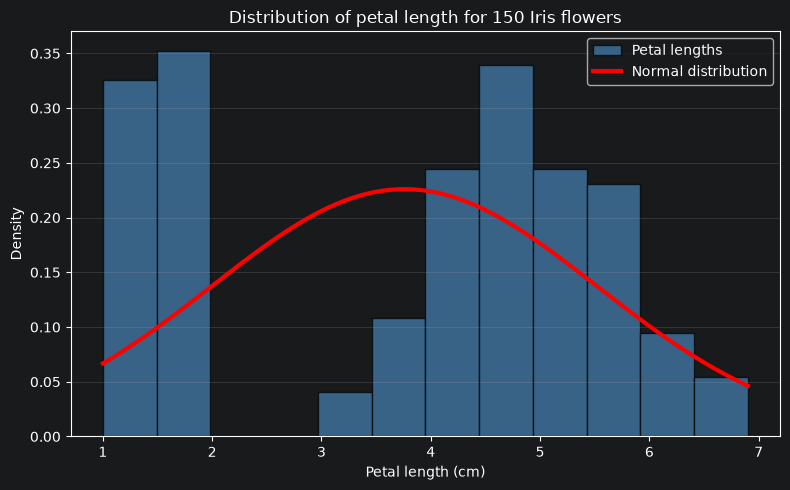

In [3]:
# Calculate the mean and standard deviation of petal length
mean = iris["petal_length"].mean()
std = iris["petal_length"].std()
# Create x-values for the normal curve
x = np.linspace(iris["petal_length"].min(), iris["petal_length"].max(), 300)
# Calculate the normal density using the data's mean and standard deviation
normal_density = (1 / (std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mean) / std) ** 2)
# Create figure with 8x5 inch size
plt.figure(figsize=(8, 5))
# Plot a density histogram with 12 bins
plt.hist(iris["petal_length"], bins=12, density=True, edgecolor="black", color="steelblue", alpha=0.7, label="Petal lengths")
# Plot the normal distribution curve
plt.plot(x, normal_density, color="red", linewidth=3, label="Normal distribution")
# Add title
plt.title("Distribution of petal length for 150 Iris flowers")
# Add x-axis label
plt.xlabel("Petal length (cm)")
# Add y-axis label
plt.ylabel("Density")
# Add a legend
plt.legend()
# Add light horizontal gridlines
plt.grid(axis="y", alpha=0.25)
# Auto-adjust subplot spacing
plt.tight_layout()
# Display the plot
plt.show()

The overall histogram combines all three species. The next plot shows a separate histogram for each species, with a normal distribution based on that species' mean and standard deviation.

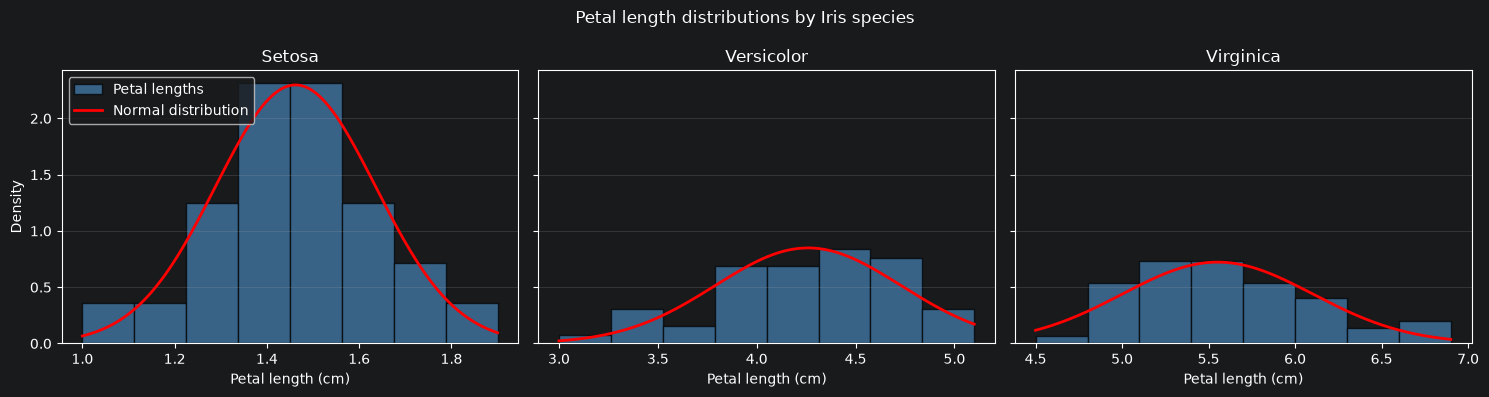

In [4]:
# List the three flower species
species = iris["species"].unique()
# Create one subplot for each species
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
# Plot a histogram and fitted normal curve for each species
# zip() documentation: https://docs.python.org/3/library/functions.html#zip
for axis, flower_species in zip(axes, species):
    # Select petal lengths for the current species
    lengths = iris.loc[iris["species"] == flower_species, "petal_length"]
    # Calculate the current species' mean
    mean = lengths.mean()
    # Calculate the current species' standard deviation
    std = lengths.std()
    # Create x-values for the normal curve
    x = np.linspace(lengths.min(), lengths.max(), 200)
    # Calculate the normal density using this species' mean and standard deviation
    normal_density = (1 / (std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mean) / std) ** 2)
    # Plot the species' density histogram
    axis.hist(lengths, bins=8, density=True, edgecolor="black", color="steelblue", alpha=0.7, label="Petal lengths")
    # Plot the fitted normal distribution
    axis.plot(x, normal_density, color="red", linewidth=2, label="Normal distribution")
    # Add the species name as the subplot title
    axis.set_title(flower_species.capitalize())
    # Label the x-axis
    axis.set_xlabel("Petal length (cm)")
    # Add light horizontal gridlines
    axis.grid(axis="y", alpha=0.25)
# Add the shared y-axis label
axes[0].set_ylabel("Density")
# Add a legend to the first subplot
axes[0].legend()
# Add a title for the full figure
fig.suptitle("Petal length distributions by Iris species")
# Adjust spacing between subplots
fig.tight_layout()
# Display the plots
plt.show()

The three histograms show that each species has a different typical petal length. The normal curves provide a simple comparison for the shape of each species' measurements.

The following table reports the mean and standard deviation of petal length for the complete dataset and for each species.

In [5]:
# Calculate the mean and standard deviation for each species
species_stats = iris.groupby("species")["petal_length"].agg(["mean", "std"])
# Add the complete-dataset statistics as a new row
species_stats.loc["Complete dataset"] = iris["petal_length"].agg(["mean", "std"])
# Move the complete-dataset row to the top
petal_length_stats = species_stats.loc[["Complete dataset"] + list(species_stats.index[:-1])]
# Display the results rounded to two decimal places
petal_length_stats.round(2)

,mean,std
species,,
Complete dataset,3.76,1.77
setosa,1.46,0.17
versicolor,4.26,0.47
virginica,5.55,0.55


## End